In [ ]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=False)

import glob, os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix)
import kagglehub

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

tetuan_dir = kagglehub.dataset_download("fedesoriano/electric-power-consumption")
tetuan_file = glob.glob(os.path.join(tetuan_dir, "**", "*.csv"), recursive=True)[0]
print(tetuan_file)

names = {"datetime": "Datetime", "temperature": "Temperature", "humidity": "Humidity",
         "windspeed": "WindSpeed", "generaldiffuseflows": "GeneralDiffuseFlows",
         "diffuseflows": "DiffuseFlows",
         "zone1powerconsumption": "PowerConsumption_Zone1", "powerconsumptionzone1": "PowerConsumption_Zone1",
         "zone2powerconsumption": "PowerConsumption_Zone2", "powerconsumptionzone2": "PowerConsumption_Zone2",
         "zone3powerconsumption": "PowerConsumption_Zone3", "powerconsumptionzone3": "PowerConsumption_Zone3"}

raw = pd.read_csv(tetuan_file)
raw.columns = [names[re.sub("[^a-z0-9]", "", c.lower())] for c in raw.columns]
raw["Datetime"] = pd.to_datetime(raw["Datetime"], format="%m/%d/%Y %H:%M")
raw = raw.sort_values("Datetime").drop_duplicates("Datetime").set_index("Datetime")

zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
weather = ["Temperature", "Humidity", "WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows"]

try:
    uci_dir = kagglehub.dataset_download("uciml/electric-power-consumption-data-set")
    uci_file = glob.glob(os.path.join(uci_dir, "**", "*.txt"), recursive=True)[0]
    uci = pd.read_csv(uci_file, sep=";", na_values="?", low_memory=False)
    print("UCI dataset:", uci.shape)
    print(list(uci.columns))
    print(uci.isna().sum().to_dict())
    display(uci.head(3))
    del uci
except Exception as e:
    print("UCI dataset not loaded:", e)

print(raw.shape)
print(raw.index.min(), raw.index.max())
print(raw.index.to_series().diff().value_counts().head(3))
print(raw.isna().sum().sum(), "missing values,", raw.index.duplicated().sum(), "duplicate timestamps")
display(raw.head())
display(raw.describe().T.round(2))

100%|██████████| 1.36M/1.36M [00:00<00:00, 59.0MB/s]

Extracting files...
/root/.cache/kagglehub/datasets/fedesoriano/electric-power-consumption/versions/1/powerconsumption.csv


100%|██████████| 19.4M/19.4M [00:00<00:00, 106MB/s] 

Extracting files...


UCI dataset: (2075259, 9)
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
{'Date': 0, 'Time': 0, 'Global_active_power': 25979, 'Global_reactive_power': 25979, 'Voltage': 25979, 'Global_intensity': 25979, 'Sub_metering_1': 25979, 'Sub_metering_2': 25979, 'Sub_metering_3': 25979}


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0


(52416, 8)
2017-01-01 00:00:00 2017-12-30 23:50:00
Datetime
0 days 00:10:00    52415
Name: count, dtype: int64
0 missing values, 0 duplicate timestamps


,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Datetime,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


,count,mean,std,min,25%,50%,75%,max
Temperature,52416.0,18.81,5.82,3.25,14.41,18.78,22.89,40.01
Humidity,52416.0,68.26,15.55,11.34,58.31,69.86,81.40,94.80
WindSpeed,52416.0,1.96,2.35,0.05,0.08,0.09,4.92,6.48
GeneralDiffuseFlows,52416.0,182.70,264.40,0.00,0.06,5.04,319.60,1163.00
DiffuseFlows,52416.0,75.03,124.21,0.01,0.12,4.46,101.00,936.00
PowerConsumption_Zone1,52416.0,32344.97,7130.56,13895.70,26310.67,32265.92,37309.02,52204.40
PowerConsumption_Zone2,52416.0,21042.51,5201.47,8560.08,16980.77,20823.17,24713.72,37408.86
PowerConsumption_Zone3,52416.0,17835.41,6622.17,5935.17,13129.33,16415.12,21624.10,47598.33


0 missing values after cleaning
min total demand: 36785.0


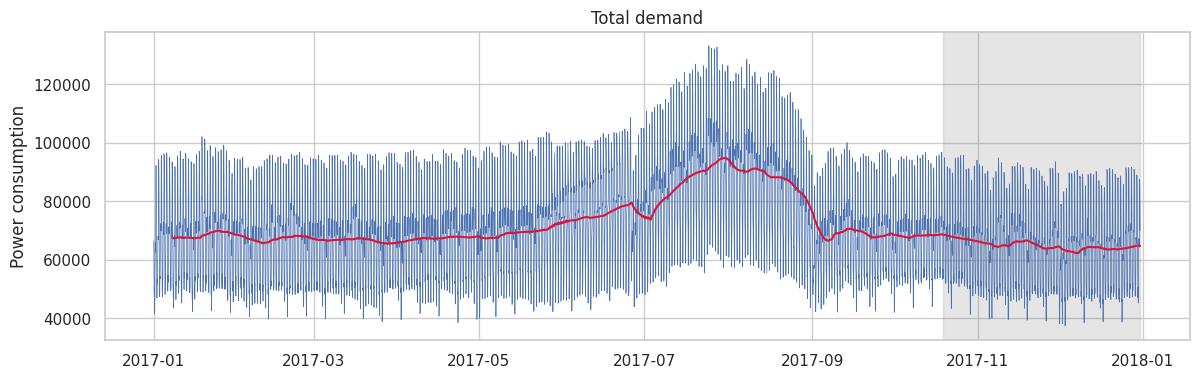

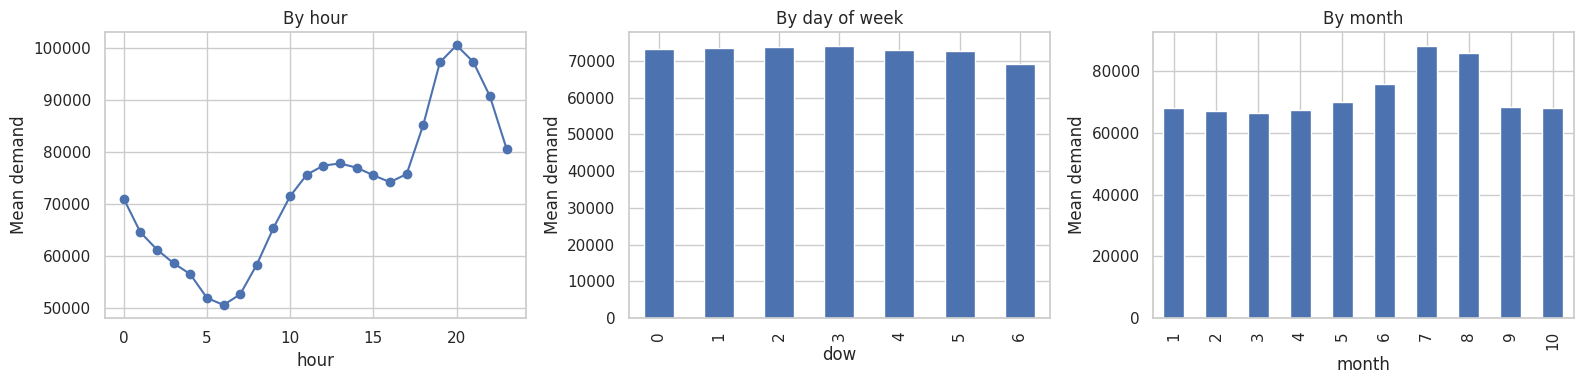

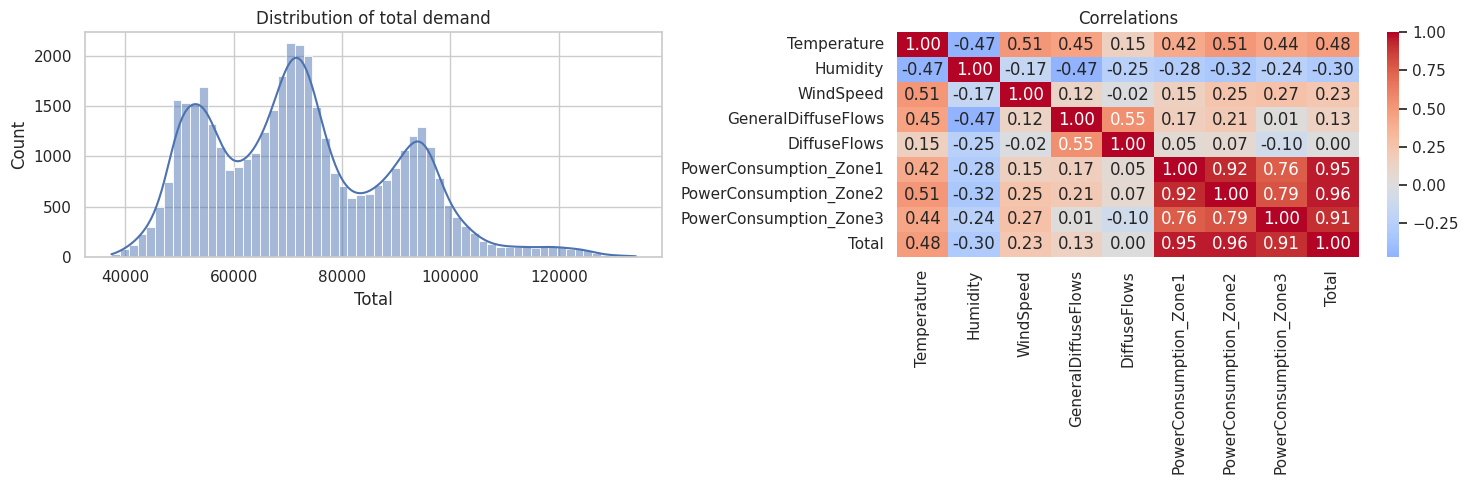

In [ ]:
df = raw.copy()
df[zones] = df[zones].mask(df[zones] <= 0)
df["Humidity"] = df["Humidity"].where(df["Humidity"].between(0, 100))
for c in ["WindSpeed", "GeneralDiffuseFlows", "DiffuseFlows"]:
    df[c] = df[c].where(df[c] >= 0)

df = df.reindex(pd.date_range(df.index.min(), df.index.max(), freq="10min"))
df[zones + weather] = df[zones + weather].ffill(limit=6)
df["Total"] = df[zones].sum(axis=1, min_count=3)

print(df.isna().sum().sum(), "missing values after cleaning")
print("min total demand:", round(df["Total"].min(), 1))

n = len(df)
t_train_end = df.index[int(n * 0.6)]
t_val_end = df.index[int(n * 0.8)]
dev = df[df.index < t_val_end].copy()
dev["hour"] = dev.index.hour
dev["dow"] = dev.index.dayofweek
dev["month"] = dev.index.month

fig, ax = plt.subplots(figsize=(14, 4))
hourly = df["Total"].resample("60min").mean()
ax.plot(hourly.index, hourly, lw=0.5)
ax.plot(hourly.index, hourly.rolling(168).mean(), color="crimson")
ax.axvspan(t_val_end, df.index.max(), color="grey", alpha=0.2)
ax.set_title("Total demand")
ax.set_ylabel("Power consumption")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
dev.groupby("hour")["Total"].mean().plot(ax=axes[0], marker="o", title="By hour")
dev.groupby("dow")["Total"].mean().plot.bar(ax=axes[1], title="By day of week")
dev.groupby("month")["Total"].mean().plot.bar(ax=axes[2], title="By month")
for a in axes:
    a.set_ylabel("Mean demand")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(dev["Total"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Distribution of total demand")
sns.heatmap(dev[weather + zones + ["Total"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlations")
plt.tight_layout()
plt.show()

In [ ]:
H = 6
LAGS = [1, 2, 3, 6, 12, 36, 72, 144]


def build(frame, h):
    total = frame["Total"]
    f = pd.DataFrame(index=frame.index)
    f["total_now"] = total
    for i, z in enumerate(zones, 1):
        f[f"zone{i}_now"] = frame[z]
    for lag in LAGS:
        f[f"lag_{lag}"] = total.shift(lag)
    f["same_time_yesterday"] = total.shift(144 - h)
    f["same_time_last_week"] = total.shift(1008 - h)
    for w in [6, 36, 144]:
        f[f"roll_mean_{w}"] = total.rolling(w).mean()
    for w in [36, 144]:
        f[f"roll_std_{w}"] = total.rolling(w).std()
    f["change_1h"] = total - total.shift(6)
    for c in weather:
        f[c.lower()] = frame[c]
    f["temp_change_1h"] = frame["Temperature"] - frame["Temperature"].shift(6)
    f["temp_roll_144"] = frame["Temperature"].rolling(144).mean()
    tt = frame.index + pd.Timedelta(minutes=10 * h)
    f["target_hour"] = tt.hour
    f["hour_sin"] = np.sin(2 * np.pi * (tt.hour + tt.minute / 60) / 24)
    f["hour_cos"] = np.cos(2 * np.pi * (tt.hour + tt.minute / 60) / 24)
    f["target_dow"] = tt.dayofweek
    f["target_weekend"] = (tt.dayofweek >= 5).astype(int)
    y = total.shift(-h).rename("target")
    ok = f.notna().all(axis=1) & y.notna()
    return f[ok], y[ok], pd.Series(tt, index=frame.index)[ok]


X, y, tgt_time = build(df, H)

cut = X.index[len(X) // 2]
bad = df.copy()
cols = zones + weather + ["Total"]
bad.loc[bad.index > cut, cols] = bad.loc[bad.index > cut, cols] * 1.7 + 1000
Xb, _, _ = build(bad, H)
common = X.index[X.index <= cut].intersection(Xb.index)
assert (X.loc[common] - Xb.loc[common]).abs().max().max() < 1e-9
print("feature leakage check passed")

gap = pd.Timedelta(minutes=10 * H)
tr = X.index < t_train_end
va = (X.index >= t_train_end + gap) & (X.index < t_val_end)
te = X.index >= t_val_end + gap
X_train, y_train = X[tr], y[tr]
X_val, y_val = X[va], y[va]
X_test, y_test = X[te], y[te]
tt_test = tgt_time[te]

print(X.shape)
print(pd.DataFrame({"rows": [len(X_train), len(X_val), len(X_test)],
                    "start": [X_train.index.min(), X_val.index.min(), X_test.index.min()],
                    "end": [X_train.index.max(), X_val.index.max(), X_test.index.max()]},
                   index=["train", "validation", "test"]))

feature leakage check passed
(51408, 32)
             rows               start                 end
train       30447 2017-01-07 23:00:00 2017-08-07 09:20:00
validation  10477 2017-08-07 10:30:00 2017-10-19 04:30:00
test        10472 2017-10-19 05:40:00 2017-12-30 22:50:00


In [ ]:
def score(name, yt, yp):
    yt = np.asarray(yt, float)
    yp = np.asarray(yp, float)
    ape = np.abs(yt - yp) / yt
    return {"Model": name,
            "MAE": mean_absolute_error(yt, yp),
            "RMSE": np.sqrt(mean_squared_error(yt, yp)),
            "R2": r2_score(yt, yp),
            "MAPE_%": 100 * ape.mean(),
            "Accuracy_%": 100 - 100 * ape.mean(),
            "Within_5%": 100 * (ape <= 0.05).mean(),
            "Within_10%": 100 * (ape <= 0.10).mean()}


def naive(Xf):
    return {"Persistence": Xf["total_now"].to_numpy(),
            "Same time yesterday": Xf["same_time_yesterday"].to_numpy(),
            "Same time last week": Xf["same_time_last_week"].to_numpy()}


models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "RandomForest": RandomForestRegressor(n_estimators=150, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=SEED),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=200, min_samples_leaf=3, max_features=0.7, n_jobs=-1, random_state=SEED),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, early_stopping=False, random_state=SEED),
}

rows = []
val_pred = {}
for name, p in naive(X_val).items():
    rows.append(score(name, y_val, p))
    val_pred[name] = p

fitted = {}
for name, m in models.items():
    t0 = time.time()
    fitted[name] = clone(m).fit(X_train, y_train)
    val_pred[name] = fitted[name].predict(X_val)
    rows.append(score(name, y_val, val_pred[name]))
    print(name, round(time.time() - t0, 1), "s")

display(pd.DataFrame(rows).sort_values("MAE").round(3).reset_index(drop=True))

Ridge 0.2 s
RandomForest 97.6 s
ExtraTrees 21.2 s
HistGradientBoosting 3.5 s


,Model,MAE,RMSE,R2,MAPE_%,Accuracy_%,Within_5%,Within_10%
0,Ridge,1030.197,1436.415,0.993,1.461,98.539,96.411,99.456
1,ExtraTrees,1583.937,2256.650,0.983,2.222,97.778,90.159,98.683
2,RandomForest,1645.392,2352.131,0.981,2.316,97.684,89.129,98.511
3,HistGradientBoosting,1737.807,2408.468,0.980,2.445,97.555,87.916,98.492
4,Same time yesterday,2421.828,3360.465,0.961,3.467,96.533,77.541,93.700
5,Same time last week,3966.222,6070.115,0.873,5.552,94.448,63.453,85.416
6,Persistence,4819.681,6711.711,0.845,6.509,93.491,51.293,73.781


In [ ]:
spaces = {
    "HistGradientBoosting": {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [200, 300, 500],
                             "max_leaf_nodes": [15, 31, 63], "min_samples_leaf": [20, 50, 100],
                             "l2_regularization": [0.0, 1.0, 10.0]},
    "ExtraTrees": {"n_estimators": [150, 250], "max_depth": [None, 20], "min_samples_leaf": [1, 3, 5],
                   "max_features": [0.5, 0.7, 1.0]},
}

candidates = dict(models)
cv = TimeSeriesSplit(n_splits=3, gap=H)
for name, space in spaces.items():
    t0 = time.time()
    search = RandomizedSearchCV(clone(models[name]), space, n_iter=6, cv=cv,
                                scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=1)
    search.fit(X_train, y_train)
    tuned = f"{name} (tuned)"
    candidates[tuned] = search.best_estimator_
    val_pred[tuned] = search.best_estimator_.predict(X_val)
    rows.append(score(tuned, y_val, val_pred[tuned]))
    print(name, round(time.time() - t0, 1), "s", search.best_params_)

val_table = pd.DataFrame(rows).sort_values("MAE").reset_index(drop=True)
display(val_table.round(3))

best_name = val_table[~val_table["Model"].isin(naive(X_val))].iloc[0]["Model"]
print("best on validation:", best_name)

HistGradientBoosting 77.2 s {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 0.0}
ExtraTrees 353.2 s {'n_estimators': 150, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': None}


,Model,MAE,RMSE,R2,MAPE_%,Accuracy_%,Within_5%,Within_10%
0,Ridge,1030.197,1436.415,0.993,1.461,98.539,96.411,99.456
1,ExtraTrees,1583.937,2256.650,0.983,2.222,97.778,90.159,98.683
2,ExtraTrees (tuned),1630.679,2349.186,0.981,2.291,97.709,88.890,98.377
3,HistGradientBoosting (tuned),1632.847,2258.109,0.982,2.302,97.698,89.358,98.731
4,RandomForest,1645.392,2352.131,0.981,2.316,97.684,89.129,98.511
5,HistGradientBoosting,1737.807,2408.468,0.980,2.445,97.555,87.916,98.492
6,Same time yesterday,2421.828,3360.465,0.961,3.467,96.533,77.541,93.700
7,Same time last week,3966.222,6070.115,0.873,5.552,94.448,63.453,85.416
8,Persistence,4819.681,6711.711,0.845,6.509,93.491,51.293,73.781


best on validation: Ridge


In [ ]:
final_model = clone(candidates[best_name]).fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
test_pred = final_model.predict(X_test)

test_rows = [score(k, y_test, v) for k, v in naive(X_test).items()]
test_rows.append(score("FINAL: " + best_name, y_test, test_pred))
test_table = pd.DataFrame(test_rows)
display(test_table.round(3))

final = test_table.iloc[-1]
persist = test_table.iloc[0]
print()
print("test MAE:", round(final["MAE"], 1))
print("test RMSE:", round(final["RMSE"], 1))
print("test R2:", round(final["R2"], 4))
print("test accuracy (100 - MAPE):", round(final["Accuracy_%"], 2), "%")
print("90% target met:", final["Accuracy_%"] >= 90)
print("MAE reduction vs persistence:", round(100 * (1 - final["MAE"] / persist["MAE"]), 1), "%")

,Model,MAE,RMSE,R2,MAPE_%,Accuracy_%,Within_5%,Within_10%
0,Persistence,4179.295,5937.321,0.823,6.465,93.535,51.175,74.990
1,Same time yesterday,2116.442,3215.427,0.948,3.384,96.616,79.326,91.740
2,Same time last week,2048.573,2819.770,0.960,3.250,96.750,81.589,94.834
3,FINAL: Ridge,940.151,1300.344,0.992,1.497,98.503,96.620,99.494



test MAE: 940.2
test RMSE: 1300.3
test R2: 0.9915
test accuracy (100 - MAPE): 98.5 %
90% target met: True
MAE reduction vs persistence: 77.5 %


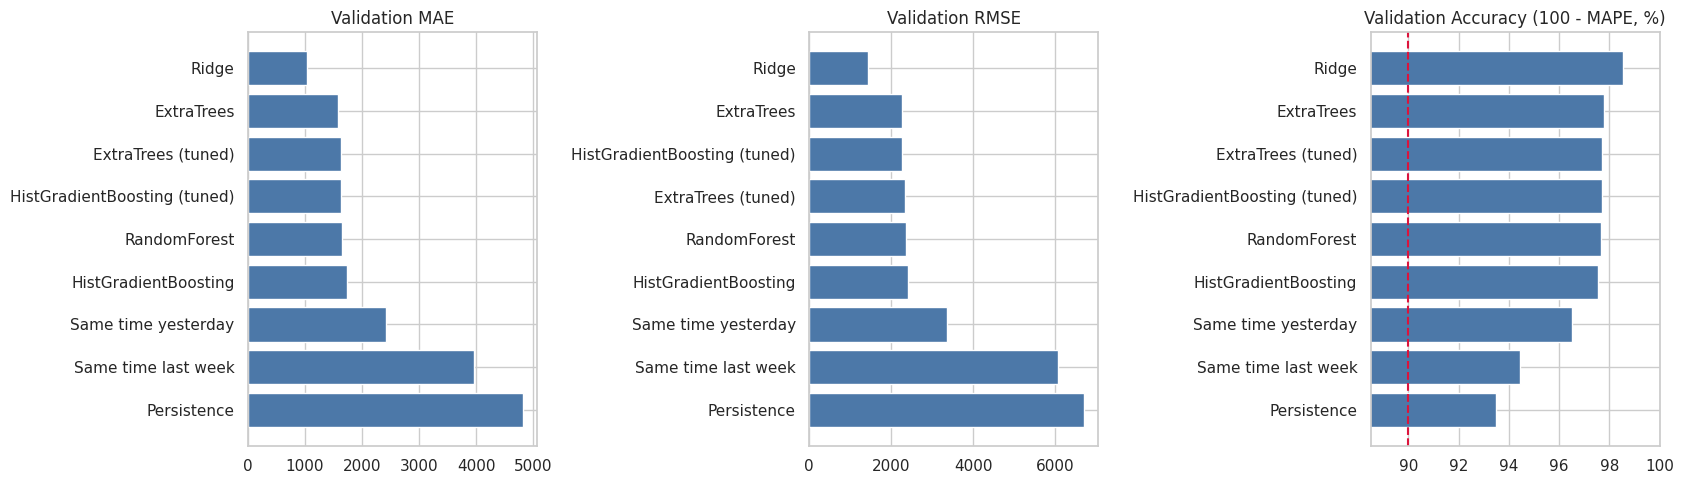

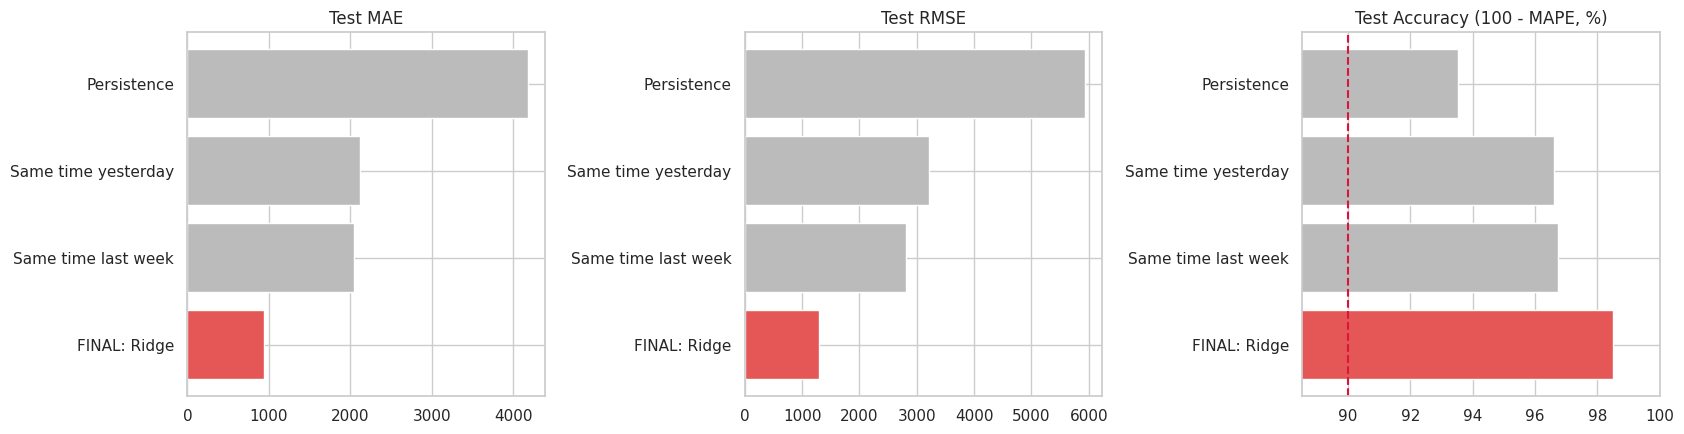

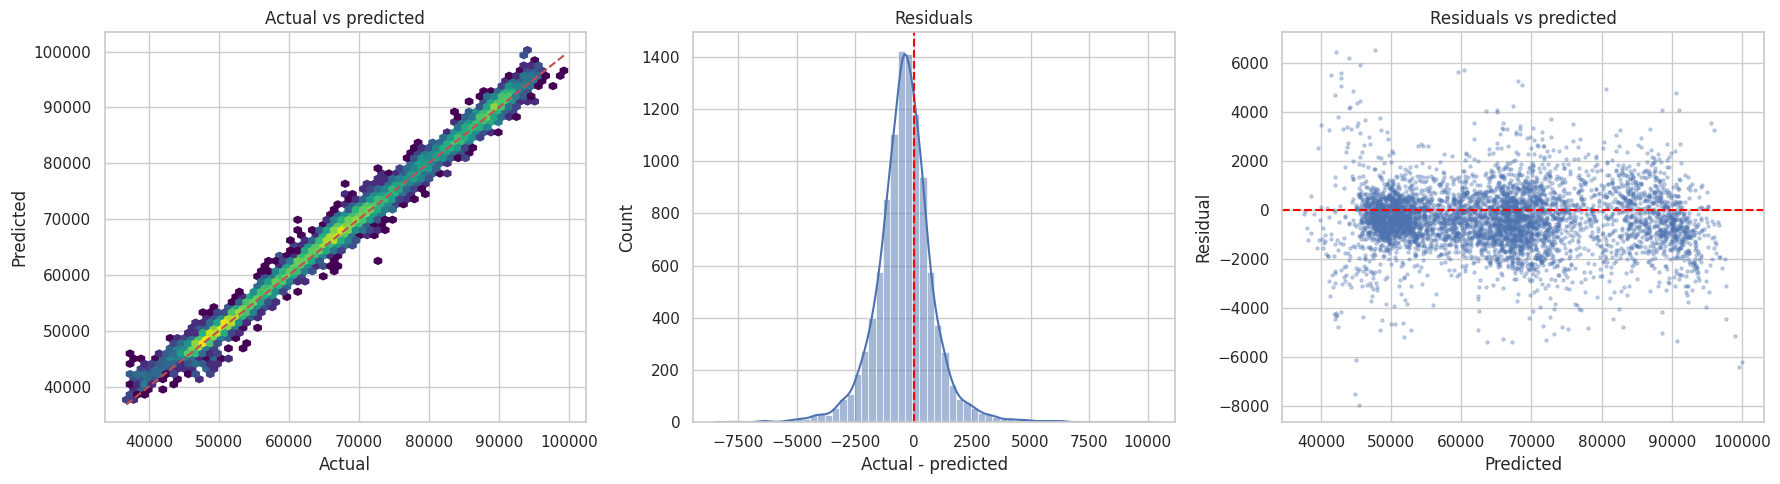

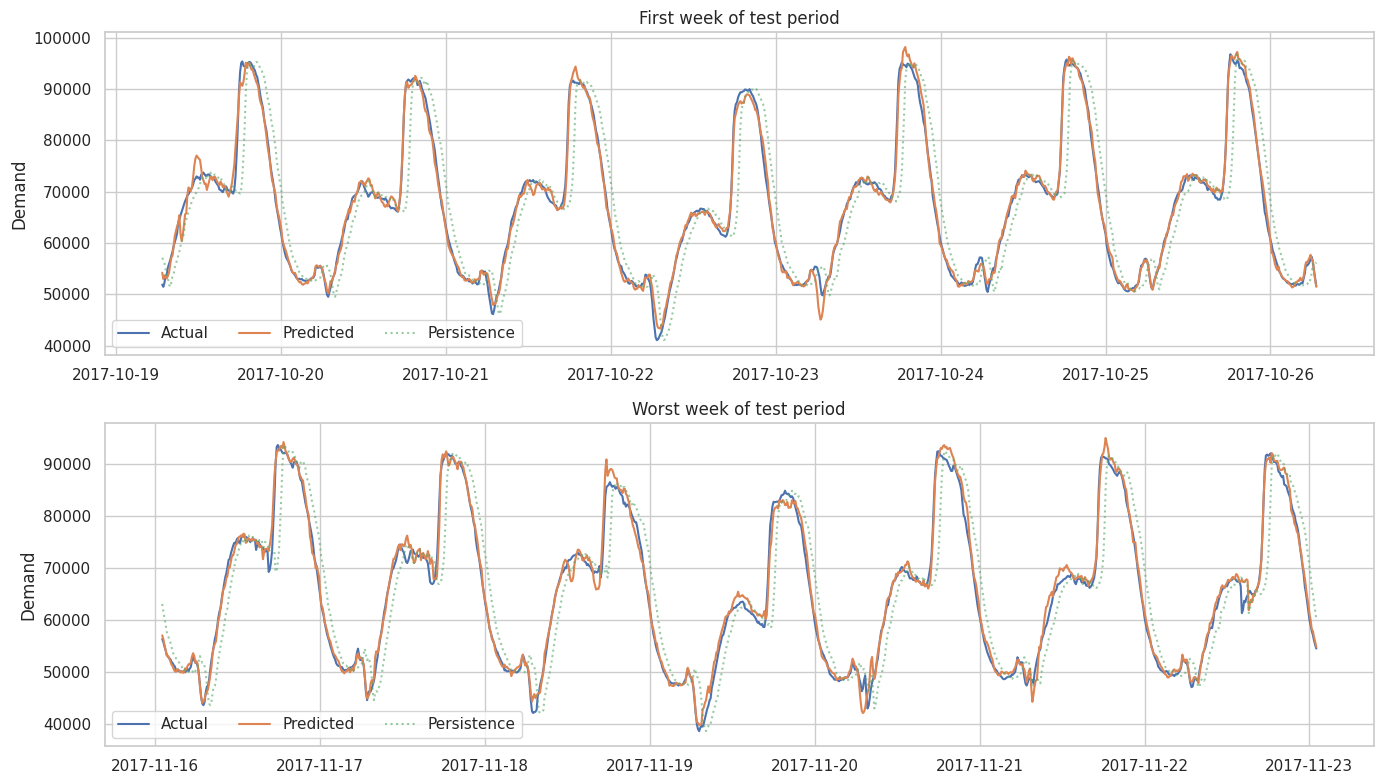

In [ ]:
res = pd.DataFrame({"time": tt_test.values, "actual": y_test.to_numpy(), "pred": test_pred,
                    "persist": X_test["total_now"].to_numpy(),
                    "hour": X_test["target_hour"].to_numpy(), "dow": X_test["target_dow"].to_numpy()},
                   index=X_test.index)
res["resid"] = res["actual"] - res["pred"]
res["abs_err"] = res["resid"].abs()
res["ape"] = 100 * res["abs_err"] / res["actual"]
res["ape_persist"] = 100 * (res["actual"] - res["persist"]).abs() / res["actual"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, col, t in zip(axes, ["MAE", "RMSE", "Accuracy_%"], ["MAE", "RMSE", "Accuracy (100 - MAPE, %)"]):
    d = val_table.sort_values(col, ascending=(col != "Accuracy_%"))
    ax.barh(d["Model"], d[col], color="#4C78A8")
    ax.invert_yaxis()
    ax.set_title("Validation " + t)
    if col == "Accuracy_%":
        ax.axvline(90, color="crimson", ls="--")
        ax.set_xlim(max(0, d[col].min() - 5), 100)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col, t in zip(axes, ["MAE", "RMSE", "Accuracy_%"], ["MAE", "RMSE", "Accuracy (100 - MAPE, %)"]):
    ax.barh(test_table["Model"], test_table[col], color=["#BBBBBB"] * 3 + ["#E45756"])
    ax.invert_yaxis()
    ax.set_title("Test " + t)
    if col == "Accuracy_%":
        ax.axvline(90, color="crimson", ls="--")
        ax.set_xlim(max(0, test_table[col].min() - 5), 100)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hexbin(res["actual"], res["pred"], gridsize=60, cmap="viridis", mincnt=1, bins="log")
lo, hi = res["actual"].min(), res["actual"].max()
axes[0].plot([lo, hi], [lo, hi], "r--")
axes[0].set_title("Actual vs predicted")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
sns.histplot(res["resid"], bins=60, kde=True, ax=axes[1])
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title("Residuals")
axes[1].set_xlabel("Actual - predicted")
s = res.sample(min(5000, len(res)), random_state=SEED)
axes[2].scatter(s["pred"], s["resid"], s=5, alpha=0.3)
axes[2].axhline(0, color="red", ls="--")
axes[2].set_title("Residuals vs predicted")
axes[2].set_xlabel("Predicted")
axes[2].set_ylabel("Residual")
plt.tight_layout()
plt.show()

weekly = res["abs_err"].resample("7D").mean()
starts = [res.index.min(), weekly.idxmax()]
titles = ["First week of test period", "Worst week of test period"]
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
for ax, st, t in zip(axes, starts, titles):
    part = res.loc[st: st + pd.Timedelta(days=7)]
    ax.plot(part["time"], part["actual"], label="Actual")
    ax.plot(part["time"], part["pred"], label="Predicted")
    ax.plot(part["time"], part["persist"], label="Persistence", ls=":", alpha=0.6)
    ax.set_title(t)
    ax.set_ylabel("Demand")
    ax.legend(ncol=3)
plt.tight_layout()
plt.show()

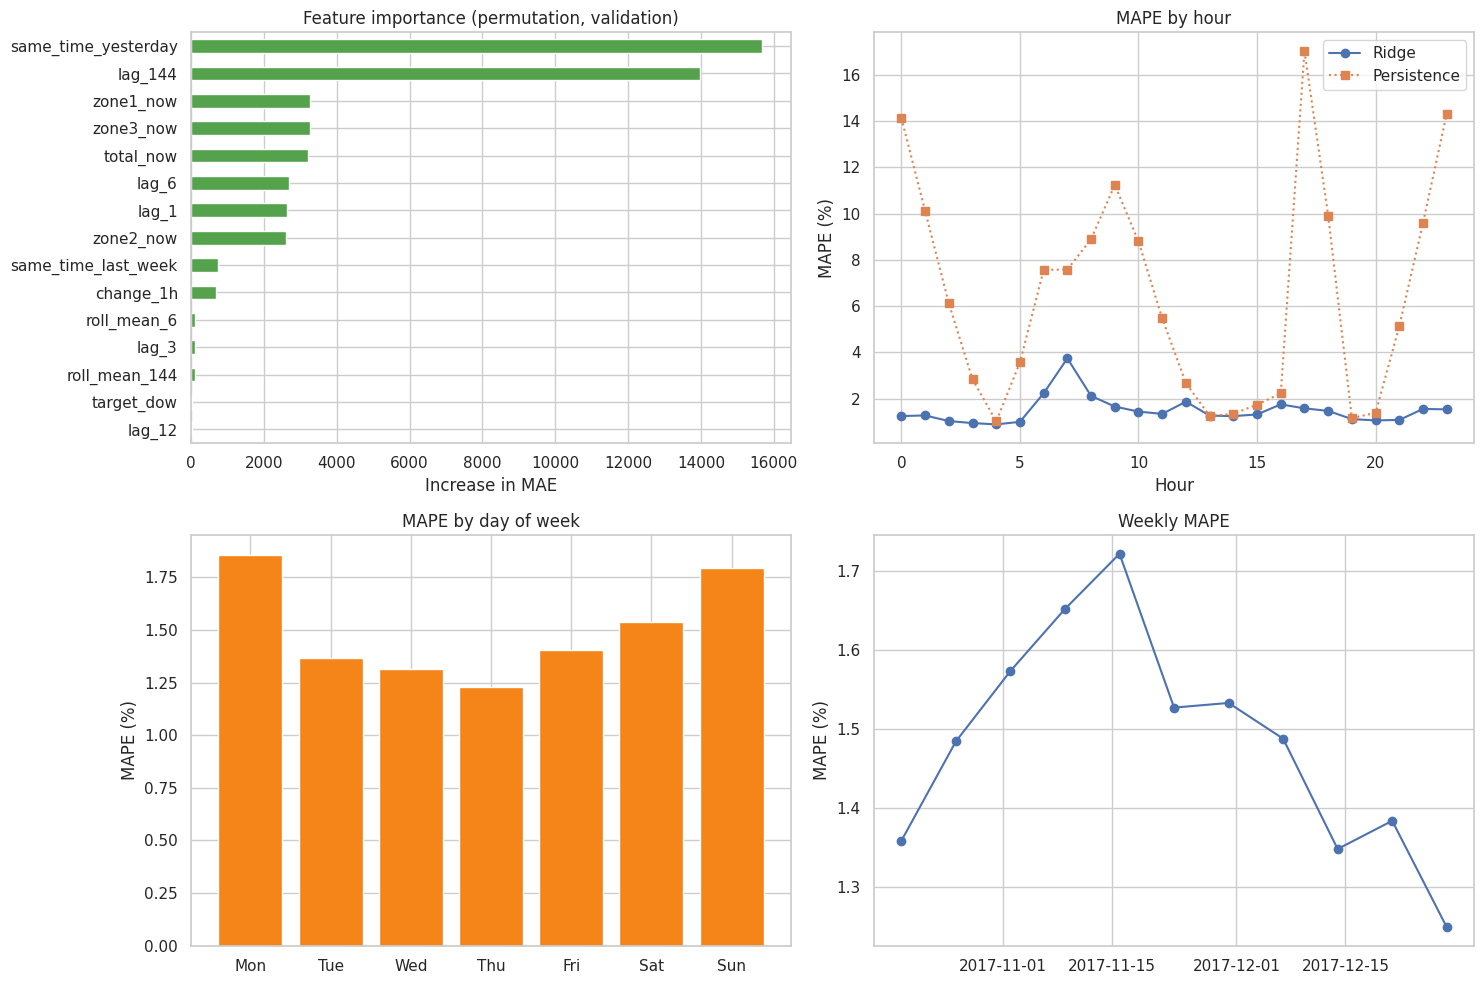

,Model,Persistence,Yesterday
minutes,,,
10,99.33,98.79,96.53
30,98.44,96.62,96.53
60,97.50,93.49,96.53
180,96.96,82.93,96.55
360,96.85,73.32,96.57
720,96.93,68.48,96.57
1440,96.71,96.57,96.57


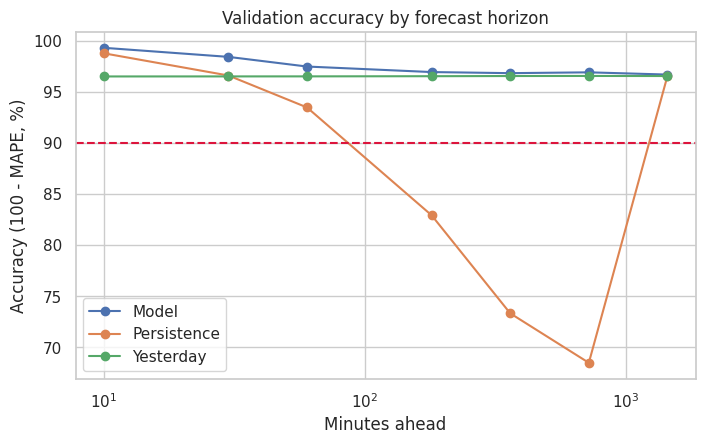

In [ ]:
diag = clone(candidates[best_name]).fit(X_train, y_train)
idx = np.random.default_rng(SEED).choice(len(X_val), size=min(3000, len(X_val)), replace=False)
perm = permutation_importance(diag, X_val.iloc[idx], y_val.iloc[idx], scoring="neg_mean_absolute_error",
                              n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X.columns).sort_values().tail(15)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
imp.plot.barh(ax=axes[0, 0], color="#54A24B")
axes[0, 0].set_title("Feature importance (permutation, validation)")
axes[0, 0].set_xlabel("Increase in MAE")

h = res.groupby("hour")[["ape", "ape_persist"]].mean()
axes[0, 1].plot(h.index, h["ape"], marker="o", label=best_name)
axes[0, 1].plot(h.index, h["ape_persist"], marker="s", ls=":", label="Persistence")
axes[0, 1].set_title("MAPE by hour")
axes[0, 1].set_xlabel("Hour")
axes[0, 1].set_ylabel("MAPE (%)")
axes[0, 1].legend()

d = res.groupby("dow")["ape"].mean().reindex(range(7))
axes[1, 0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], d.values, color="#F58518")
axes[1, 0].set_title("MAPE by day of week")
axes[1, 0].set_ylabel("MAPE (%)")

w = res["ape"].resample("7D").mean()
axes[1, 1].plot(w.index, w.values, marker="o")
axes[1, 1].set_title("Weekly MAPE")
axes[1, 1].set_ylabel("MAPE (%)")
plt.tight_layout()
plt.show()

hz = []
for minutes in [10, 30, 60, 180, 360, 720, 1440]:
    k = minutes // 10
    Xh, yh, _ = build(df, k)
    g = pd.Timedelta(minutes=minutes)
    a = Xh.index < t_train_end
    b = (Xh.index >= t_train_end + g) & (Xh.index < t_val_end)
    m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, early_stopping=False, random_state=SEED).fit(Xh[a], yh[a])
    hz.append({"minutes": minutes,
               "Model": score("m", yh[b], m.predict(Xh[b]))["Accuracy_%"],
               "Persistence": score("p", yh[b], Xh.loc[b, "total_now"])["Accuracy_%"],
               "Yesterday": score("y", yh[b], Xh.loc[b, "same_time_yesterday"])["Accuracy_%"]})
hz = pd.DataFrame(hz).set_index("minutes")
display(hz.round(2))
hz.plot(marker="o", figsize=(8, 4.5), logx=True)
plt.axhline(90, color="crimson", ls="--")
plt.title("Validation accuracy by forecast horizon")
plt.xlabel("Minutes ahead")
plt.ylabel("Accuracy (100 - MAPE, %)")
plt.show()

surge share of test intervals: 26.7 %


,Rule,Accuracy_%,Balanced_acc_%,Precision_%,Recall_%,F1_%,AUC
0,Ridge,98.27,98.12,95.83,97.78,96.80,1.00
1,Persistence,90.18,87.34,81.88,81.24,81.56,0.96


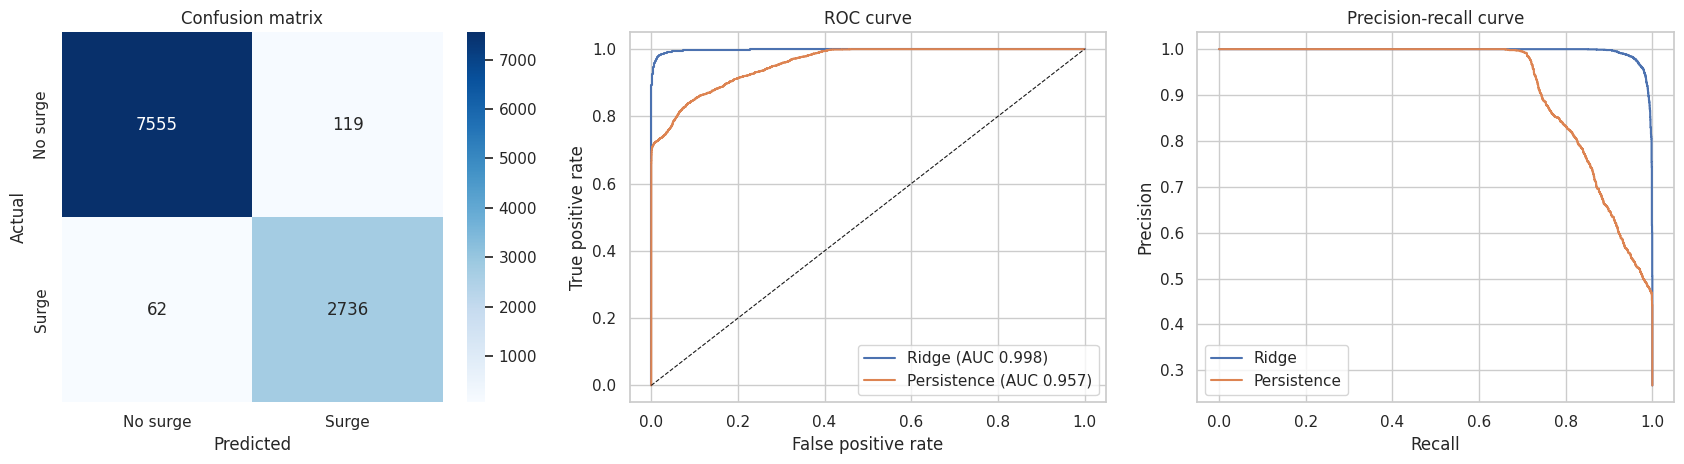

In [ ]:
ratio = 1.10
roll = X_test["roll_mean_144"].to_numpy()
y_surge = (y_test.to_numpy() >= ratio * roll).astype(int)
s_model = test_pred / roll
s_persist = X_test["total_now"].to_numpy() / roll
f_model = (s_model >= ratio).astype(int)
f_persist = (s_persist >= ratio).astype(int)


def clf(name, yp, sc):
    return {"Rule": name,
            "Accuracy_%": 100 * accuracy_score(y_surge, yp),
            "Balanced_acc_%": 100 * balanced_accuracy_score(y_surge, yp),
            "Precision_%": 100 * precision_score(y_surge, yp, zero_division=0),
            "Recall_%": 100 * recall_score(y_surge, yp, zero_division=0),
            "F1_%": 100 * f1_score(y_surge, yp, zero_division=0),
            "AUC": roc_auc_score(y_surge, sc)}


print("surge share of test intervals:", round(100 * y_surge.mean(), 1), "%")
display(pd.DataFrame([clf(best_name, f_model, s_model), clf("Persistence", f_persist, s_persist)]).round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(confusion_matrix(y_surge, f_model), annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["No surge", "Surge"], yticklabels=["No surge", "Surge"])
axes[0].set_title("Confusion matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
for nm, sc in [(best_name, s_model), ("Persistence", s_persist)]:
    fpr, tpr, _ = roc_curve(y_surge, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} (AUC {roc_auc_score(y_surge, sc):.3f})")
    p, r, _ = precision_recall_curve(y_surge, sc)
    axes[2].plot(r, p, label=nm)
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].set_title("ROC curve")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].legend()
axes[2].set_title("Precision-recall curve")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
plt.tight_layout()
plt.show()

In [ ]:
import joblib, os
os.makedirs("outputs", exist_ok=True)
joblib.dump(final_model, "outputs/best_model.joblib")
test_table.to_csv("outputs/test_results.csv", index=False)
val_table.to_csv("outputs/validation_results.csv", index=False)

print("Best model:", best_name)
print("Test MAE:", round(final["MAE"], 1), "| RMSE:", round(final["RMSE"], 1), "| R2:", round(final["R2"], 4))
print("Test accuracy (100 - MAPE):", round(final["Accuracy_%"], 2), "%")
print("Within 5%:", round(final["Within_5%"], 1), "% | within 10%:", round(final["Within_10%"], 1), "%")
print("90% target met:", bool(final["Accuracy_%"] >= 90))
print("Persistence accuracy:", round(persist["Accuracy_%"], 2), "%")

Best model: Ridge
Test MAE: 940.2 | RMSE: 1300.3 | R2: 0.9915
Test accuracy (100 - MAPE): 98.5 %
Within 5%: 96.6 % | within 10%: 99.5 %
90% target met: True
Persistence accuracy: 93.54 %
